In [2]:
import numpy as np
import scipy.constants as sc
import catppuccin
import sys; sys.path.append('../')
import adri
import matplotlib.pyplot as plt
from pygmid import Lookup as lk
pmos4 = lk('../lookup_table/035/pmos4.mat')
nmos4 = lk('../lookup_table/035/nmos4.mat')
# setup matplotlib
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams.update({"axes.grid": True})
from scipy.interpolate import interp1d
def interp1(x, y, value):
    # Interpolation function
    # Perform cubic interpolation using interp1d
    f = interp1d(x, y, kind='cubic')
    return f(value)
from IPython.display import display, HTML
import inspect, re
def print_design_summary(*args):
    # Récupère les noms des variables depuis l'appel
    frame = inspect.currentframe().f_back
    call_source = inspect.getframeinfo(frame).code_context[0].strip()
    match = re.search(r'print_design_summary\((.*)\)', call_source)
    if match:
        arg_names = [a.strip() for a in match.group(1).split(',')]
    else:
        arg_names = [f"Block {i}" for i in range(len(args))]

    def make_table(title, blk):
        items = [(k, fmt(np.asarray(v).flat[0] if not np.isscalar(v) else v, k))
                 for k, v in blk.items()]
        header = (f"<tr><td colspan='2' style='padding:8px 0 3px; font-size:20px; "
                  f"letter-spacing:.1em; opacity:.5; text-transform:uppercase; "
                  f"border-top:1px solid currentColor;'>{title}</td></tr>")
        rows = "".join(
            f"<tr><td style='padding:1px 4px 1px 0; opacity:.6; white-space:nowrap'>{k}</td>"
            f"<td style='padding:1px 0; text-align:right; font-variant-numeric:tabular-nums; "
            f"font-weight:500; white-space:nowrap'>{v}</td></tr>"
            for k, v in items)
        footer = "<tr><td colspan='2' style='border-top:1px solid currentColor; padding-top:2px'></td></tr>"
        return (f"<table style='font-family:monospace; font-size:18px; border-collapse:collapse; "
                f"color:inherit; vertical-align:top'>{header}{rows}{footer}</table>")

    tables = ""
    for name, blk in zip(arg_names, args):
        tables += f"<td style='vertical-align:top; padding-right:0px'>{make_table(name, blk)}</td>"

    display(HTML(
        f"<table style='color:inherit; border-spacing:; border-collapse:collapse'>"
        f"<tr>{tables}</tr></table>"
    ))
def fmt(val, key=""):
    if not isinstance(val, (int, float, np.floating)):
        return str(val)
    a = abs(val)
    if   a >= 1e9:  return f"{val/1e9:.4g} G"
    elif a >= 1:    return f"{val:.4g}"
    elif a >= 1e-3: return f"{val/1e-3:.4g} m"
    elif a >= 1e-6: return f"{val/1e-6:.4g} u"
    elif a >= 1e-9: return f"{val/1e-9:.4g} n"
    elif a >= 1e-12:return f"{val/1e-12:.4g} p"
    else:           return f"{val:.4e}"



# Telescopic cascode

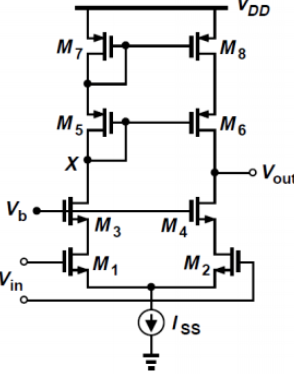 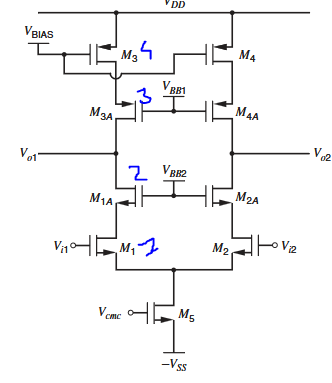

## Find GM/ID given output swing

In [2]:
#Spec
#L0 > 50 & V_SWING_P2P_DIFF = 1.8
d = {}
G = 4
beta_max = 1 / (1 + G)
beta = 3/4 * beta_max
kappa = 0.7

#Sizing the output branch

#Vout_cm = 1.35
###Choose gm_id with output common mode
#Vout_swing = 1.8 p2p_diff -> each output 0.9 p2p -> 1.35 +- 0.45
VDD = 2.7
VCM = 1.25
V_SWING_P2P_DIFF = 0.5
VOUT_CM_HIGH = VCM+V_SWING_P2P_DIFF/2
VOUT_CM_LOW = VCM-V_SWING_P2P_DIFF/2
VDS_MOS = VOUT_CM_LOW/3
VS = 0.624
print('2 MOS pour', VOUT_CM_HIGH)
print('3 MOS pour', VOUT_CM_LOW)
gm_id = 2/(VDS_MOS)
print('VDS_MOS =  ', VDS_MOS)
print('gm_id > ', gm_id)
print('On prend gm_id = 12')
##On prend gm_id = 15
gm_ID = 12
d['gm_IDcas'] = gm_ID
d['gm_gain'] = 25

2 MOS pour 1.5
3 MOS pour 1.0
VDS_MOS =   0.3333333333333333
gm_id >  6.0
On prend gm_id = 12


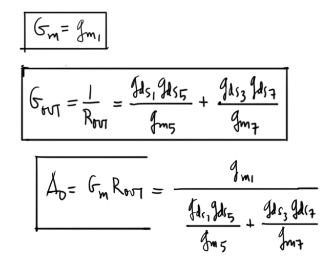 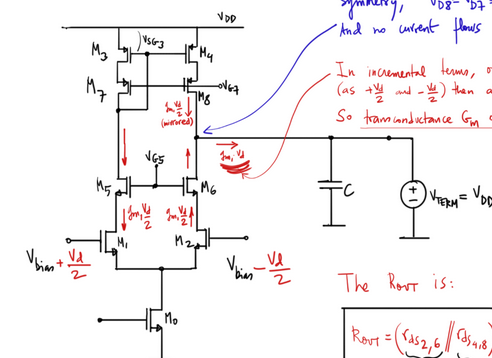

## Équation de départ
$$\frac{g_{m1}}{\frac{g_{ds1} \cdot g_{ds5}}{g_{m5}} + \frac{g_{ds3} \cdot g_{ds7}}{g_{m7}}}$$

## Équation en ratio de gm_gds et ratio gm_gm
$$\frac{1}{\frac{1}{\left(\frac{g_{m1}}{g_{ds1}}\right)\left(\frac{g_{m5}}{g_{ds5}}\right)} + \frac{g_{m3}}{g_{m1}} \cdot \frac{1}{\left(\frac{g_{m3}}{g_{ds3}}\right)\left(\frac{g_{m7}}{g_{ds7}}\right)}}$$

## Estimation du gain, mais pour le gain précis en mode SC, il faudra calculer le beta
Si input MOS trop gros, le beta casse le gain


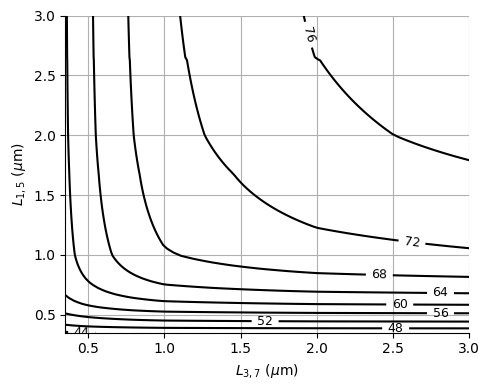

In [3]:
#Set L sweep for plot 
L = np.linspace(0.35, 3, 100)

d['gm_gain'] = 20
gm3_gm1 = 0.5
gm_id1 = d['gm_gain']
gm_id3 = gm_id1 * gm3_gm1

#Compute gain param
gm_gds1 = nmos4.lookup('GM_GDS', GM_ID = gm_id1, L = L, VDS = VDS_MOS, VSB = VS)
gm_gds5 = nmos4.lookup('GM_GDS', GM_ID = gm_id1, L = L, VDS = VCM-VDS_MOS-VS, VSB = VDS_MOS+VS)
gm_gds7 = pmos4.lookup('GM_GDS', GM_ID = gm_id3, L = L, VDS = VOUT_CM_HIGH/2, VSB = 0)
gm_gds3 = pmos4.lookup('GM_GDS', GM_ID = gm_id3, L = L, VDS = VOUT_CM_HIGH/2, VSB =  VOUT_CM_HIGH/2)

L0 = np.zeros((len(L), len(L)))
#Copute L0 for range of Lcascode
for i in range(len(L)):
    L0[i, :] =   1 / (    1/(gm_gds1*gm_gds5) + gm3_gm1*(1/(gm_gds3[i]*gm_gds7[i]))) * beta * kappa
L0 = 20*np.log10(L0)
# Plotting
fig, ax = plt.subplots(figsize=(5, 4))
C = ax.contour(L, L, L0, colors='k', levels=8)
ax.clabel(C, fmt='%d', fontsize=9)
ax.set_xlabel(r'$L_{3,7}$ ($\mu$m)')
ax.set_ylabel(r'$L_{1,5}$ ($\mu$m)')
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams.update({"axes.grid": True})
plt.tight_layout()
plt.show()

ID = 35e-6
d['L1'] = 0.5
d['Lcas'] = 1
#Fill output with MOS charac
m1 = adri.get_all_mos(nmos4, GM_ID= gm_id1,L=d['L1'], GM=gm_id1*ID, ID=ID,VDS = VDS_MOS)
m5 = adri.get_all_mos(nmos4, GM_ID= gm_id1, L=d['Lcas'], ID=ID, VDS=VCM-VDS_MOS-VS)
m7 = adri.get_all_mos(pmos4, GM_ID= gm_id3, L=d['Lcas'], ID=ID, VDS=VOUT_CM_HIGH/2)
m3 = adri.get_all_mos(pmos4, GM_ID= gm_id3, L=d['Lcas'], ID=ID, VDS=VOUT_CM_HIGH/2)

kB = 1.3806488e-23
temp = 300
CL = 215e-15*4
alpha = (2)*0.85 #same as 5T OT1 ? si on ignore les cascode
perf = {}
beta = 0.723 #same as 5T OT1 ?
perf['vnoise'] = np.sqrt(alpha / beta * kB*temp/CL)

adri.print_design_summary(m1,m5,m7,m3,perf)

## Optimization with beta loop
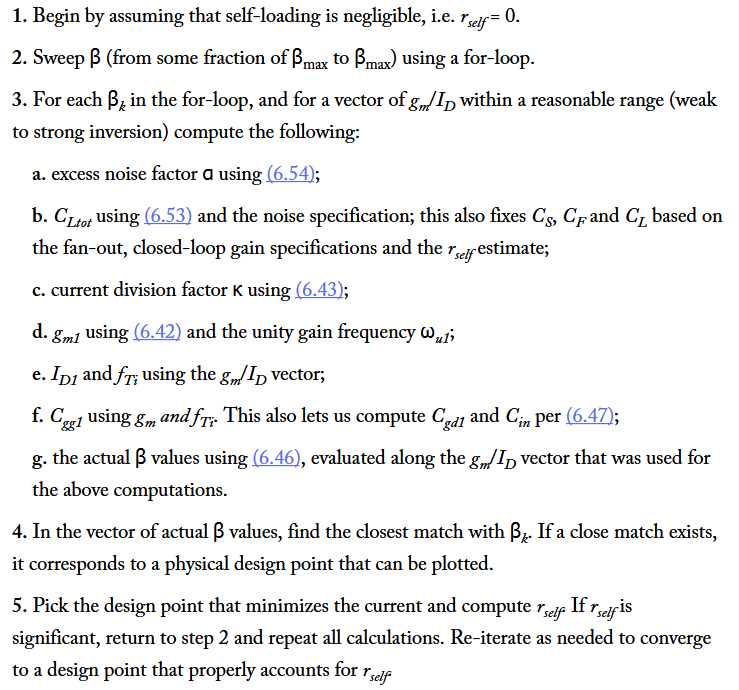

# Telescopic cascode function vectorized

In [15]:
def telesopic_cascode(nmoslk, pmoslk, s, d): ##Version Matriced
    """
    Size a folded-cascode amplifier using the gm/ID methodology.

    Sweeps β and gm/ID simultaneously to find the design points that meet
    the noise and speed specifications, then computes the self-loading
    capacitance at each point.

    nmoslk / pmoslk are gm/ID lookup tables for the NMOS and PMOS devices.

    s must contain:
        fu1       — unity-gain frequency (Hz)
        vod_noise — output-referred noise voltage (V)
        FO        — fan-out
        G         — closed-loop gain
        vod_final — voltage ouput step max
        ed — erreur settling %
        VDD
        VCM
        V_SWING_P2P_DIFF

    d must contain:
        gm_ID1   — gm/ID sweep vector for the input transistor (S/A)
        beta     — feedback factor sweep vector
        L1       — input transistor length (µm)
        Lcas     — cascode length (µm)
        gm_IDcas — cascode gm/ID operating point (S/A)
        gamma    — excess noise coefficient
        cself    — self-loading estimate, set to 0 on first pass (F)

    Returns m1 (ID, gm_ID) and p (cltot, cself) at each matched design point.
    """
    VDD = s['VDD']
    VCM = s['VCM']
    V_SWING_P2P_DIFF = s['V_SWING_P2P_DIFF']
    VOUT_CM_HIGH = VCM+V_SWING_P2P_DIFF/2
    VOUT_CM_LOW = VCM-V_SWING_P2P_DIFF/2
    VDS_MOS = VOUT_CM_LOW/3
    VS = s['VS']
    #gm3_gm1 = d['gm3_gm1']
    beta_max = 1 / (1 + s['G'])
    kB = 1.3806488e-23
    temp = 300
    # ── Device lookups over the gm/ID sweep vector ────────────────────────────
    gm_gds1  = pmoslk.look_up('GM_GDS',  GM_ID=d['gm_ID1'],   L=d['L1'])
    wt1      = pmoslk.look_up('GM_CGG',  GM_ID=d['gm_ID1'],   L=d['L1'])
    cdd_gm7  = pmoslk.look_up('CDD_GM',  GM_ID=d['gm_IDcas'], L=d['Lcas'])
    cdd_gm5  = nmoslk.look_up('CDD_GM',  GM_ID=d['gm_ID1'], L=d['Lcas'])

    # ── Step 2 : sweep β — broadcast to 2D (N_beta, N_gm_ID1) ────────────────
    beta   = d['beta'][:, None]    # (N, 1)
    gm_ID1 = d['gm_ID1'][None, :] # (1, M)

    # Step 3a. Excess noise factor α (eq. 6.54)
    # alpha = 2 * d['gamma'] * (1 + 3 * d['gm_IDcas'] / gm_ID1)
    alpha = 2 * d['gamma'] * (gm_ID1 / gm_ID1)
    #alpha = 2 * d['gamma']

    # Step 3b. C_Ltot from noise spec (eq. 6.53) — also fixes C_S, C_F, C_L
    cltot = alpha / beta * kB * temp / s['vod_noise']**2
    cltot[cltot<= 200e-15] = 200e-15
    CF    = (cltot - d['cself']) / (s['FO'] * s['G'] + 1 - beta)
    CS    = s['G'] * CF
    CL   = s['FO'] * CS

    # Step 3c. Current division factor κ (eq. 6.43)
    #kappa = 1 / (1 + gm_ID1 / (gm_gds1 * d['gm_IDcas']) + 2 / gm_gds2)

    #Slewing compute X, then more accurate wu1 
    X = s['vod_final'] * beta / 2 * gm_ID1
    wu1 = 1 / s['ts']*(X - 1 + np.log(1/(s['ed']*X)))

    # Step 3d. g_m1 from settling formula above 
    #gm1 = 2 * np.pi * s['fu1'] * cltot / beta / kappa
    gm1 = wu1 * cltot / beta

    # Step 3e. I_D1 and f_Ti from the gm/ID vector
    ID1 = gm1 / gm_ID1

    # Step 3f. C_gg1 from g_m and f_Ti → compute C_gd1 and C_in (eq. 6.47)
    cgs1 = gm1 / wt1
    #cin  = cgs1 * (1 + cgd_cgg1 * gm_ID1 / d['gm_IDcas'])
    cin  = cgs1

    # Step 3g. Actual β values along the gm/ID vector (eq. 6.46)
    beta_actual = CF / (CF + CS + cin)

    # ── Step 4 : find closest match between β_actual and β_k ─────────────────
    idx = np.argmin(np.abs(beta_actual - beta), axis=1)  # (N,)
    j   = np.arange(len(d['beta']))
    


    m1_gm1 = gm1[j, idx]
    m1_gm_id1 = d['gm_ID1'][idx]
    ID1 = gm1[j, idx] / d['gm_ID1'][idx]
    
    #Cascode bias MOS
    VGS_M5 = nmoslk.lookupVGS(GM_ID=m1_gm_id1, VDS=VDS_MOS, L=d['Lcas'])
    vgs_bias = VDS_MOS + VGS_M5 
    #vgs_bias = 1
    ibias_mosbias = ID1 / 10
    L_mosbias = 7
    vgs_bias = vgs_bias
    JD_mosbias = nmos4.look_up('ID_W', VGS=vgs_bias, VDS=vgs_bias, L=L_mosbias, VSB=VS)
    JD_mosbias2 = nmos4.look_up('ID_W', VGS=vgs_bias, VDS=vgs_bias, L=L_mosbias, VSB=VS+vgs_bias)

    mosbias = {
                'bias_needed > ' : VDS_MOS + VGS_M5,
                'ibias_mosbias' : ibias_mosbias,
                'vgs_bias' : vgs_bias,
                'L' : L_mosbias,
                'W' : ibias_mosbias / JD_mosbias,
                'W_mosbias2' : ibias_mosbias / JD_mosbias2,
               }

    # mosbias = adri.get_all_mos(nmoslk, GM_ID=25, L=d['Lcas'], ID=ibias_mosbias, VDS=VGS_M5, VSB = VS)
    # print(mosbias)
    #Fill output with MOS charac
    m3 = adri.get_all_mos(pmoslk, GM_ID=d['gm_IDcas'], L=d['Lcas'], ID=ID1, VDS=VOUT_CM_HIGH/2)
    m7 = adri.get_all_mos(pmoslk, GM_ID=d['gm_IDcas'], L=d['Lcas'], ID=ID1, VDS=VOUT_CM_HIGH/2)
    m5 = adri.get_all_mos(nmoslk, GM_ID=m1_gm_id1, L=d['Lcas'], ID=ID1, VDS=VDS_MOS)
    m1 = adri.get_all_mos(nmoslk, GM_ID=m1_gm_id1,L=d['L1'], GM=m1_gm1, ID=ID1, VDS = VDS_MOS)

    #Compute gain param
    gm_gds3 = pmoslk.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS = VOUT_CM_HIGH/2, VSB =  VOUT_CM_HIGH/2)
    gm_gds7 = pmoslk.lookup('GM_GDS', GM_ID = d['gm_IDcas'], L = d['Lcas'], VDS = VOUT_CM_HIGH/2, VSB = 0)
    gm_gds5 = nmoslk.lookup('GM_GDS', GM_ID = m1_gm_id1, L = d['Lcas'], VDS = VCM-VDS_MOS-VS, VSB = VDS_MOS+VS)
    gm_gds1 = nmoslk.lookup('GM_GDS', GM_ID = m1_gm_id1, L = d['L1'], VDS = VDS_MOS, VSB = VS)

    gm1 = m1_gm_id1 * ID1
    gm3_gm1 = d['gm_IDcas'] / m1_gm_id1

    #kappa = 1 / ( 1 + gds1 / gm3 + 2 / gm_gds2)
    L0 = 20*np.log10(1/(1/(gm_gds1*gm_gds5)+gm3_gm1*(1/(gm_gds3*gm_gds7))) * beta)

    p = {
        'cltot': cltot[j, idx],
        'cself': m1['ID'] * d['gm_IDcas'] * (cdd_gm5 + cdd_gm7),
        #'beta' : beta,
        'L0' : L0,
        'CF' : CF,
        'CS' : CS,
        'CL' : CL,
        'fu1' : wu1 * 1/(2*np.pi),
        'beta_betamax' : beta_actual / d['beta'],
        #'FP2 / FU1' : d['fp2'] / (wu1 * 1/(2*np.pi))
    }
    return m1,m5,m7,m3,mosbias,p

### Find Lowest current & Rself versus length & gm_id1

C:\Users\Surfe\AppData\Local\Temp\ipykernel_40416\297469646.py:135: RuntimeWarning: invalid value encountered in log10
  L0 = 20*np.log10(1/(1/(gm_gds1*gm_gds5)+gm3_gm1*(1/(gm_gds3*gm_gds7))) * beta)


FP2 / FU1 == 4 for 75° phase margin and fatest settling
fp2 / s['fu1'] = np.float64(0.40931290615255245)


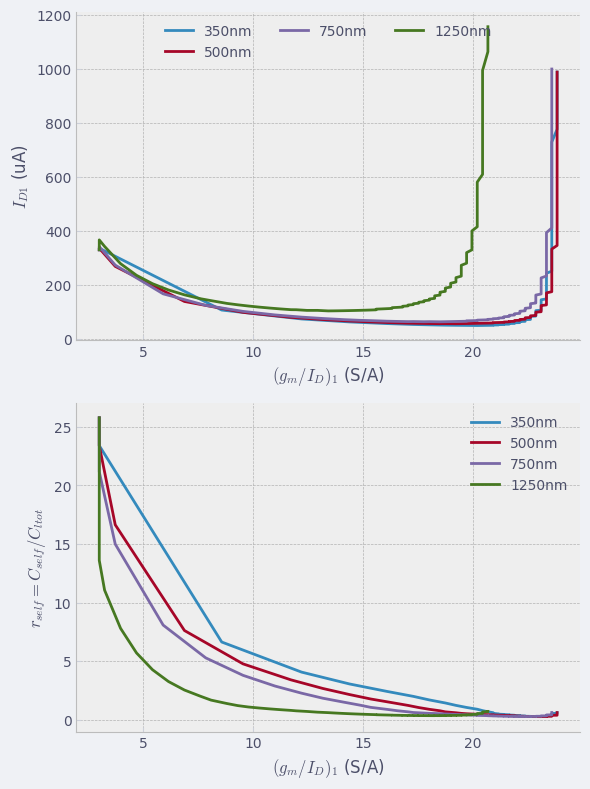

In [20]:
#Design Spec 
s = {
    'ts'        : 50e-9,
    'ed'        : 0.1/100,
    'fu1'       : 1/(2*np.pi) * np.log(1/ (0.1/100)) / 50e-9,
    'vod_noise' : 100e-6,
    'FO'        : 0.5,
    'G'         : 2,
    'vod_final' : 0.2,
    'VDD' : 2.7,
    'VCM' : 1.25,
    'V_SWING_P2P_DIFF' : 0.5,
    'VS' : 0.6
}
beta_max = 1 / (1 + s['G'])
s['fu1'] = 1 / (2 * np.pi) * np.log(1 / s['ed']) / s['ts']

# Constants for another design
d = {
    'gamma': 0.8,
    'Lcas': 2,
    'gm_IDcas': 10,
    'cself': 0,
    'gm_ID1': np.linspace(3, 27, 100),
    'beta': beta_max * np.linspace(0.2, 1, 100)
}
fp2 = 9e6
d['fp2'] = fp2
# Channel length sweep
L1 = [0.35, 0.5, 0.75, 1.25]
m1 = []
p = []

for Li in L1:
    d['L1'] = Li
    mi,m5,m7,m3,mbias,pi = telesopic_cascode(nmos4, pmos4, s, d)
    m1.append(mi)
    p.append(pi)

# Plotting setup
plt.style.use("bmh")
fig, axs = plt.subplots(2, 1, figsize=(6, 8))

# Plot ID versus gm/ID for different L values
for i, length in enumerate(L1):
    label = f'{length * 1e3:.0f}nm'  # Convert L from meters to nm for label
    axs[0].plot(m1[i]['GM_ID'], m1[i]['ID'] * 1e6, label=label)  # ID in mA
axs[0].set_xlabel(r'$(g_m/I_D)_1$ (S/A)')
axs[0].set_ylabel(r'$I_{D1}$ (uA)')
axs[0].legend(loc='upper center', ncol=3, frameon=False)
axs[0].grid(True)

# Plot cself/cltot versus gm/ID for different L values
for i, length in enumerate(L1):
    label = f'{length * 1e3:.0f}nm'
    axs[1].plot(m1[i]['GM_ID'], p[i]['cself'] / p[i]['cltot'], label=label)
axs[1].set_xlabel(r'$(g_m/I_D)_1$ (S/A)')
axs[1].set_ylabel(r'$r_{self} = C_{self}/C_{ltot}$')
axs[1].legend(loc='best', frameon=False)
axs[1].grid(True)

print("FP2 / FU1 == 4 for 75° phase margin and fatest settling")
adri.cool_print(fp2 / s['fu1'])

plt.tight_layout()
plt.show()

In [ ]:
#Design Spec 
s = {
    'ts'        : 50e-9,
    'ed'        : 0.1/100,
    'fu1'       : 1/(2*np.pi) * np.log(1/ (0.1/100)) / 50e-9,
    'vod_noise' : 100e-6,
    'FO'        : 4,
    'G'         : 1/4,
    'vod_final' : 0.2,
    'VDD' : 2.7,
    'VCM' : 1.25,
    'V_SWING_P2P_DIFF' : 0.5,
    'VS' : 0.6
}
beta_max = 1 / (1 + s['G'])
s['fu1'] = 1 / (2 * np.pi) * np.log(1 / s['ed']) / s['ts']

# Constants for another design
d = {
    'gamma': 0.8,
    'Lcas': 2,
    'gm_IDcas': 10,
    'cself': 0,
    'L1': 0.5,
    'gm_ID1': np.array([20]),
    'beta': np.array([beta_max * 3/4]),
    'fp2' : 9e6
}
m1,m5,m7,m3,mbias,p = telesopic_cascode(nmos4, pmos4, s, d)

adri.print_design_summary(d,s,m1,m5,m7,m3,mbias,p)


# Full design with Self loading loop+Sizing W,L 

Ibias:  = 23.9817 uA
beta_opt / beta_max  = 0.798


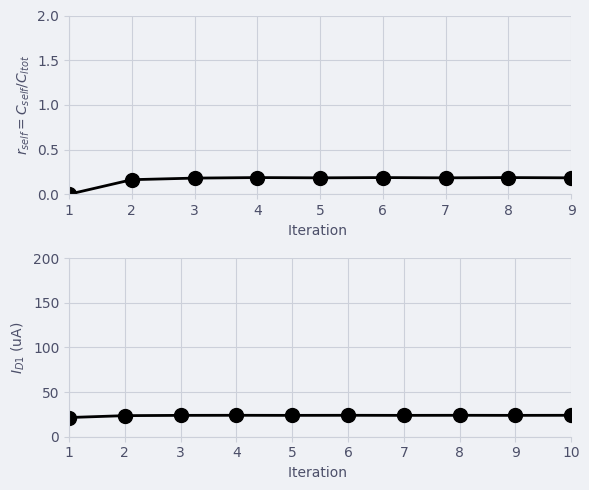

In [ ]:
#Design Spec 
s = {
    'ts'        : 200e-9,
    'ed'        : 0.01/100,
    'fu1'       : 1/(2*np.pi) * np.log(1/ (0.1/100)) / 50e-9,
    'vod_noise' : 100e-6*0.5,
    'FO'        : 4,
    'G'         : 1/4,
    'vod_final' : 0.2,
    'VDD' : 2.7,
    'VCM' : 1.25,
    'V_SWING_P2P_DIFF' : 0.5,
    'VS' : 0.6
}
beta_max = 1 / (1 + s['G'])
s['fu1'] = 1 / (2 * np.pi) * np.log(1 / s['ed']) / s['ts']

# Constants for another design
d = {
    'gamma': 0.9,
    #To be adjust if noise not accurate or compute gamme
    'Lcas': 2,
    'gm_IDcas': 15,
    #'gm3_gm1':0.5,
    'L1' : 2,
    'cself': 0,
    'gm_ID1': np.linspace(5, 28, 100),
    'beta': beta_max * np.linspace(0.2, 1, 100)
}

# Self loading sweep
cself = np.zeros(10)
ID1 = np.zeros_like(cself)
gm_ID1 = np.zeros_like(cself)
cltot = np.zeros_like(cself)
beta = np.zeros_like(cself)

for i in range(len(cself)):
    d['cself'] = cself[i]
    #rint(d['cself'])
    m1,m5,m7,m3,mosbias,p = telesopic_cascode(nmos4, pmos4, s, d)
    ID1[i] = np.min(m1['ID'])
    m = np.argmin(m1['ID'])
    gm_ID1[i] = m1['GM_ID'][m]
    cltot[i] = p['cltot'][m]
    beta[i] = d['beta'][m]

    if i + 1 < len(cself):
        cself[i + 1] = p['cself'][m]

plt.style.use(catppuccin.PALETTE.latte.identifier)
# Plotting results
fig, axs = plt.subplots(2, 1, figsize=(6, 5))

# r_self vs iteration
axs[0].plot(range(1, len(cself)), cself[:-1] / cltot[:-1], 'k-o', linewidth=2, markersize=10)
axs[0].set_xlabel('Iteration ')
axs[0].set_ylabel(r'$r_{self} = C_{self}/C_{ltot}$')
axs[0].set_xlim([1, len(cself) - 1])
axs[0].set_ylim([0, 2])
axs[0].grid(True)

# ID1 vs iteration
axs[1].plot(range(1, len(ID1) + 1), ID1 * 1e6, 'k-o', linewidth=2, markersize=10)
axs[1].set_xlabel('Iteration ')
axs[1].set_ylabel(r'$I_{D1}$ (uA)')
axs[1].set_xlim([1, len(ID1)])
axs[1].set_ylim([0, 200])
axs[1].grid(True)

# Final sizing point
ID1_opt = ID1[-1]
gm_ID1_opt = gm_ID1[-1]
beta_opt = beta[-1]
CLtot = cltot[-1]
Cself = cself[-1]

print('Ibias:  = %.4f uA' % (ID1_opt*1e6))
print('beta_opt / beta_max  = %.3f' % (beta_opt / beta_max))
#print('fu1  = %.3f MHz' % (p['fu1']*1e-6))

d['gm_ID1'] =  np.array([gm_ID1_opt])
d['beta'] =  np.array([beta_opt])
m1,m5,m7,m3,mosbias,p = telesopic_cascode(nmos4, pmos4, s, d)
adri.print_design_summary(s,d,m1,m5,m7,m3,mosbias,p)

plt.tight_layout()
plt.show()

In [19]:
# Extraction pour les MOS (W est déjà en unité correcte)
mos_data = [('M1', m1), ('M5', m5), ('M7', m7), ('M3', m3), ('mosbias', mosbias)]

for name, mos in mos_data:
    w_val = mos['W'].flatten()[0]
    l_val = mos['L']
    print(f"{name}_W {w_val:.3f}u")
    print(f"{name}_L {l_val:.2f}u")

# Extraction pour les Capacités
# On multiplie par 1e15 pour passer des Farads aux femtofarads
caps = [('Cf', p['CF']), ('Cs', p['CS']), ('Cl', p['CL'])]

for name, val in caps:
    val_f = val.flatten()[0] * 1e15
    print(f"{name} {val_f:.1f}f")

# Extraction correcte de la valeur scalaire
valeur_ibias = m1['ID'].flatten()[0] *1e6
# Application du formatage avec 'f' (pour le suffixe)
print(f"ibias {valeur_ibias:.3f}u")

M1_W 48.042u
M1_L 2.00u
M5_W 48.042u
M5_L 2.00u
M7_W 167.275u
M7_L 2.00u
M3_W 167.275u
M3_L 2.00u
mosbias_W 0.664u
mosbias_L 7.00u
Cf 2791.7f
Cs 697.9f
Cl 2791.7f
ibias 23.982u


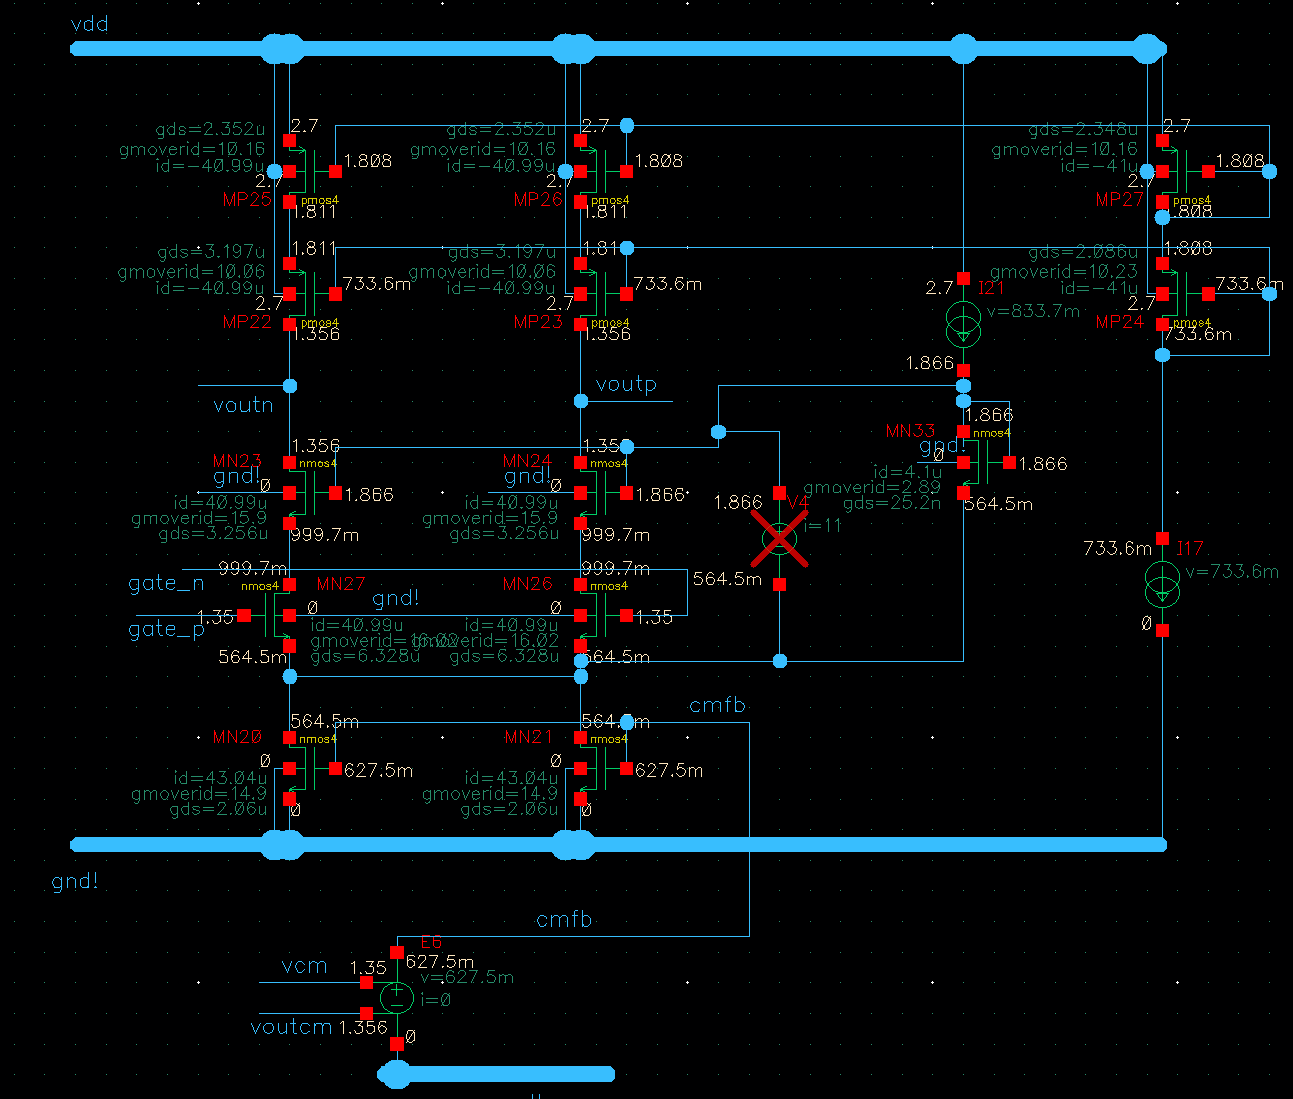  
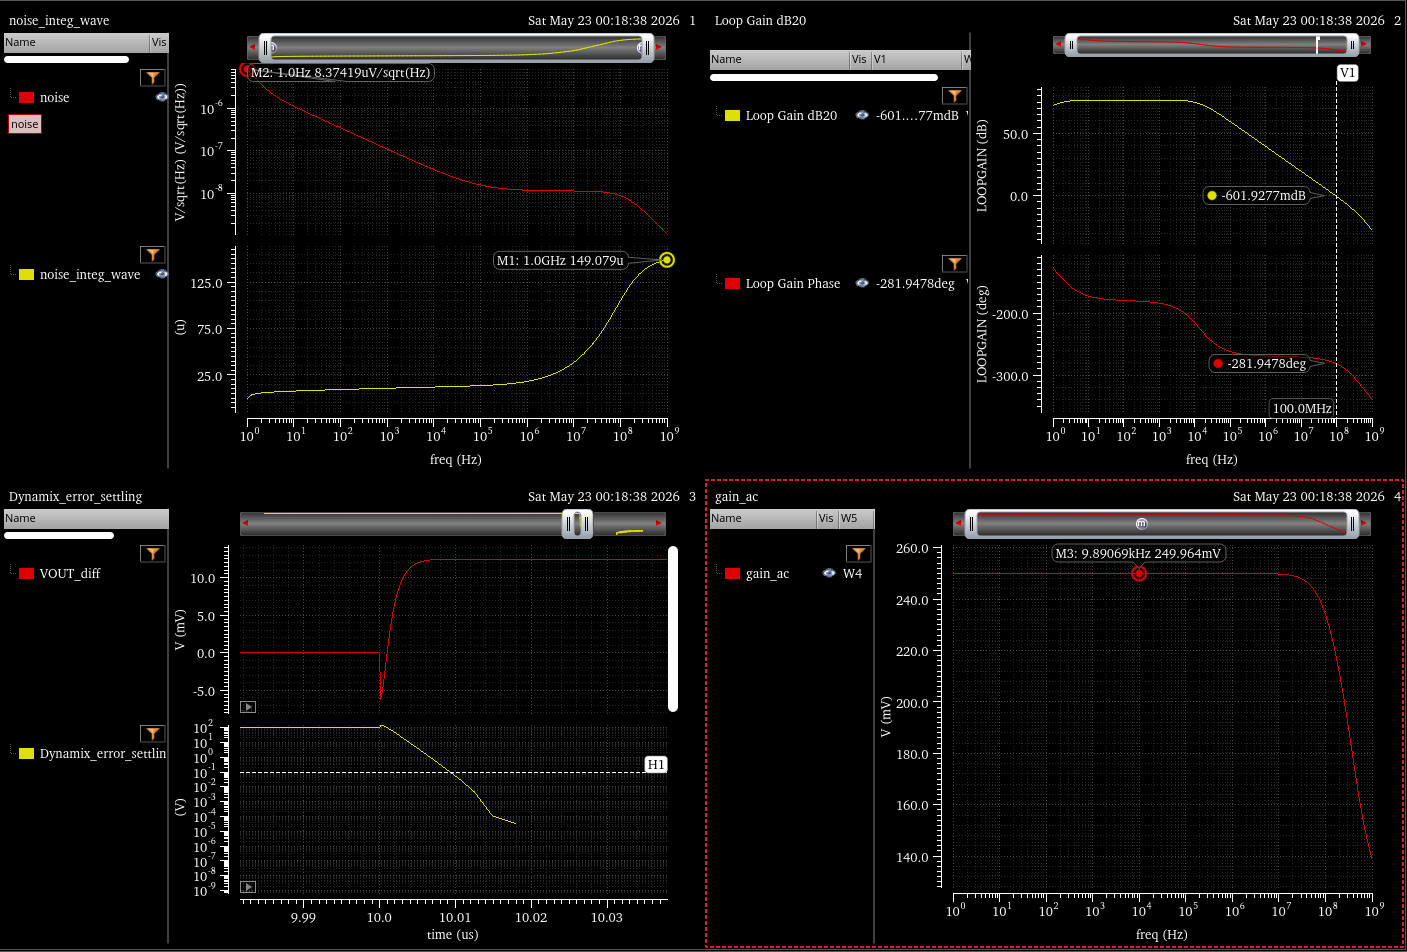 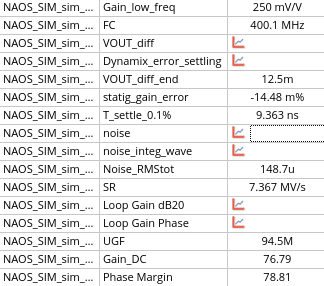

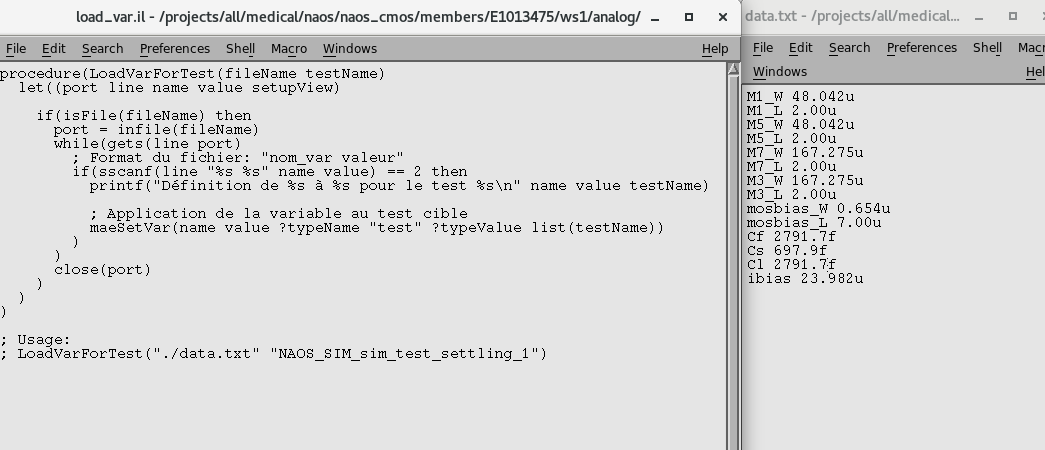

In [18]:
# Extraction pour les MOS (W est déjà en unité correcte)
mos_data = [('M1', m1), ('M5', m5), ('M7', m7), ('M3', m3), ('mosbias', mosbias)]

for name, mos in mos_data:
    w_val = mos['W'].flatten()[0]
    l_val = mos['L']
    print(f"{name}_W {w_val:.3f}u")
    print(f"{name}_L {l_val:.2f}u")

# Extraction pour les Capacités
# On multiplie par 1e15 pour passer des Farads aux femtofarads
caps = [('Cf', p['CF']), ('Cs', p['CS']), ('Cl', p['CL'])]

for name, val in caps:
    val_f = val.flatten()[0] * 1e15
    print(f"{name} {val_f:.1f}f")

# Extraction correcte de la valeur scalaire
valeur_ibias = m1['ID'].flatten()[0] *1e6
# Application du formatage avec 'f' (pour le suffixe)
print(f"ibias {valeur_ibias:.3f}u")

M1_W 48.042u
M1_L 2.00u
M5_W 48.042u
M5_L 2.00u
M7_W 167.275u
M7_L 2.00u
M3_W 167.275u
M3_L 2.00u
mosbias_W 0.664u
mosbias_L 7.00u
Cf 2791.7f
Cs 697.9f
Cl 2791.7f
ibias 23.982u
